In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from plotting_helpers import get_power_trace_df, get_job_table_df

In [ ]:
simulation_output = "W2-simulated_annealing_low_util_availability=True_50server_20260225114542" # "dr_RSR_exp_inf_low_util=0.6_W2-short-qos5_4.5_4_3.5_traditional_signal_qos0.9_20250817150403" # "W_train_inf_short_NoDR_1000server_20250312223016" # "W2_NoDR_50server_20250308132744" # "availability_50server_20250306143558" # "W2-simulated_annealing_low_util_50server_test_20250306115615"

output_dir = "../output/simulation/" + simulation_output
power_df = get_power_trace_df(output_dir)
# power_df['realSum'].iloc[2500:].max()

/Users/fatihacun/PycharmProjects/flexdc-sim/src/peacsim/notebooks/plotting_helpers.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  power_df['active_servers'] = (power_df[state_columns] != -1).sum(axis=1)
/Users/fatihacun/PycharmProjects/flexdc-sim/src/peacsim/notebooks/plotting_helpers.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  power_df['realSum_kw'] = power_df['realSum'] / 1000  # Convert to kw
/Users/fatihacun/PycharmProjects/flexdc-sim/src/peacsim/notebooks/plotting_helpers.py:12: PerformanceWarning: DataFrame 

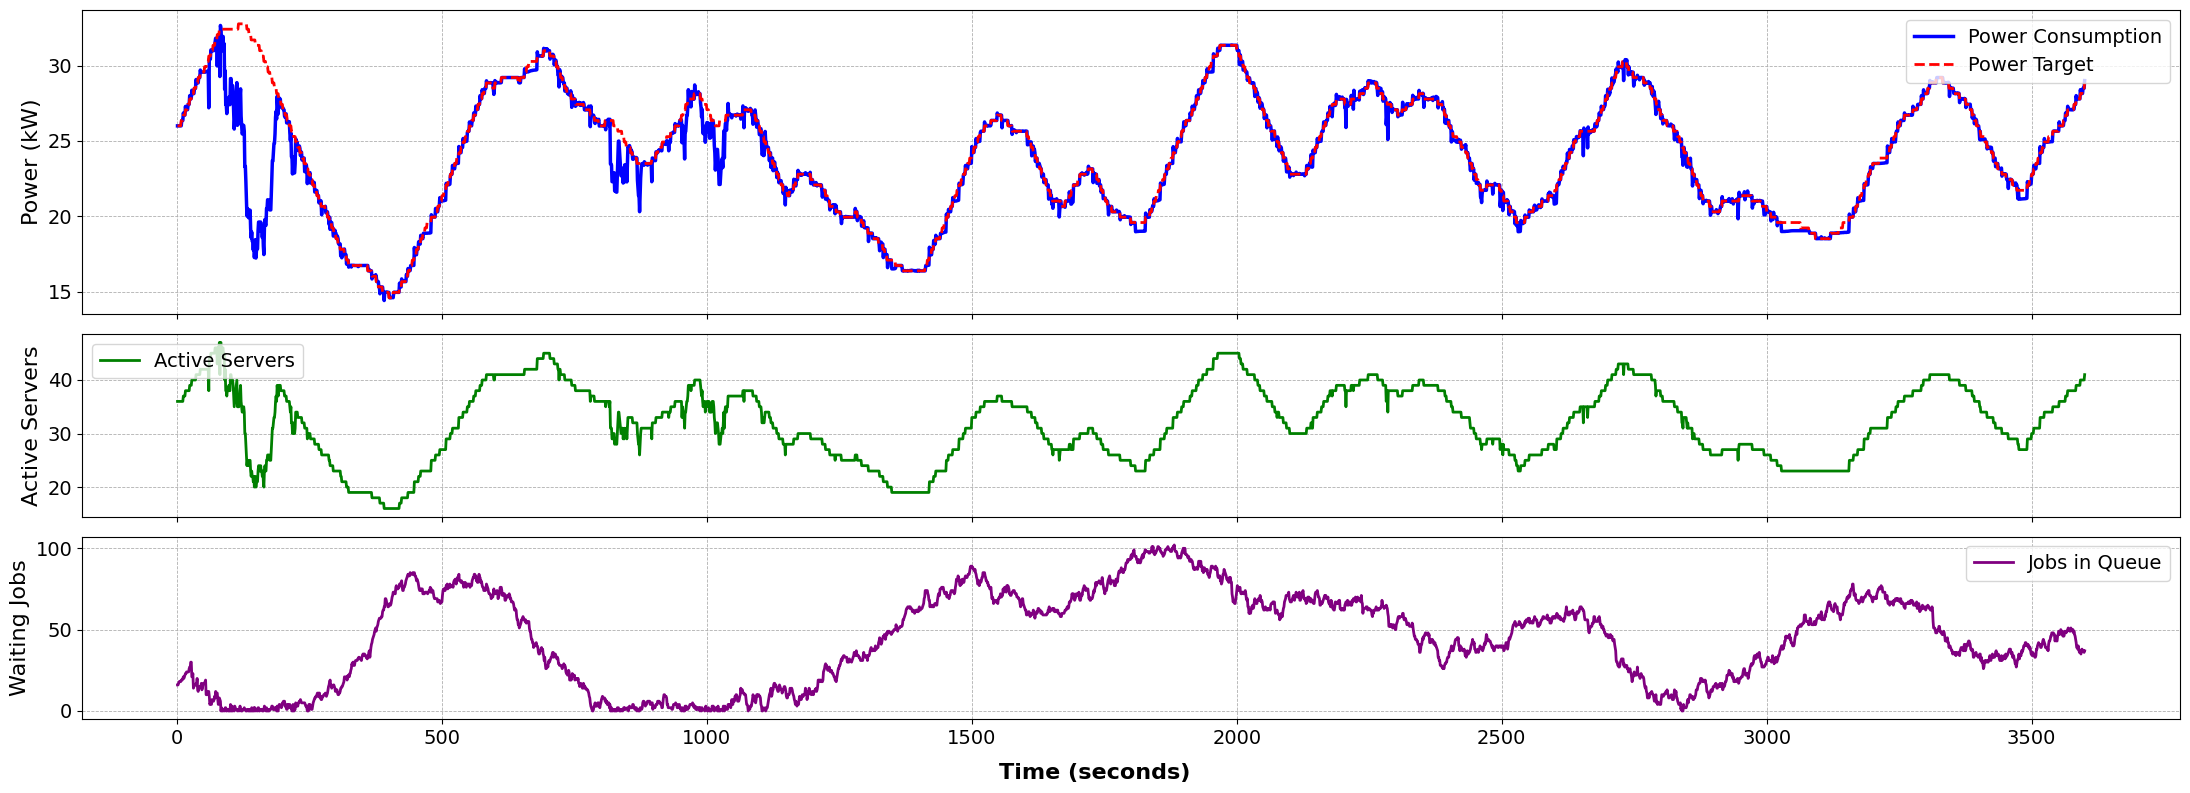

In [3]:

# Define figure and subplots with adjusted size
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(22, 8), sharex=True, gridspec_kw={'height_ratios': [1.0, 0.6, 0.6]})

# --- Top Plot: Power Consumption and Target ---
ax1.plot(power_df['time'], power_df['realSum_kw'], label='Power Consumption', linewidth=2.5, color='blue')
ax1.plot(power_df['time'], power_df['target_kw'], label='Power Target', color='red', linewidth=2, linestyle='--')
ax1.set_ylabel('Power (kW)', fontsize=16)
# ax1.set_title('Power Consumption vs Power Target Over Time', fontsize=18, fontweight='bold')
ax1.legend(fontsize=14, loc='upper right')
ax1.grid(True, linestyle='--', linewidth=0.6)
ax1.tick_params(axis='both', which='major', labelsize=14)

# --- Middle Plot: Active Servers and Power Cap (Dual Y-Axis) ---
ax2.plot(power_df['time'], power_df['active_servers'], label='Active Servers', color='green', linewidth=2)
ax2.set_ylabel('Active Servers', fontsize=16)
ax2.legend(fontsize=14, loc='upper left')
ax2.grid(True, linestyle='--', linewidth=0.6)
ax2.tick_params(axis='both', which='major', labelsize=14)

# --- Bottom Plot: Number of Waiting Jobs ---
ax3.plot(power_df['time'], power_df['waitingSum'], label='Jobs in Queue', color='purple', linewidth=2)
ax3.set_ylabel('Waiting Jobs', fontsize=16)
ax3.legend(fontsize=14, loc='upper right')
ax3.grid(True, linestyle='--', linewidth=0.6)
ax3.tick_params(axis='both', which='major', labelsize=14)

# Common x-axis label for all plots
fig.text(0.5, 0.02, 'Time (seconds)', ha='center', fontsize=16, fontweight='bold')

# Adjust layout for better spacing
plt.tight_layout(rect=[0, 0.04, 1, 1])  # Make space for the shared x-axis label

# Save as high-quality PDF
plt.savefig(f'plots/{exp_name}_power_consumption.pdf', format='pdf', dpi=300, bbox_inches='tight')

# Show the combined plot
plt.show()


In [4]:
job_table = get_job_table_df(output_dir)
display(job_table[['job_id', 'job_type_id', 'arrival_time', 'start_time', 'end_time', 'min_execution_time', 'qos_constraint']])

,job_id,job_type_id,arrival_time,start_time,end_time,min_execution_time,qos_constraint
0,0,1,0.0,0.0,30.0,28.0,4.0
1,1,2,0.0,0.0,38.0,36.0,4.0
2,2,0,0.0,0.0,27.0,25.0,3.0
3,3,2,0.0,0.0,38.0,36.0,4.0
4,4,1,0.0,0.0,30.0,28.0,4.0
...,...,...,...,...,...,...,...
3470,3470,0,3595.0,-1.0,-1.0,25.0,3.0
3471,3471,2,3597.0,-1.0,-1.0,36.0,4.0
3472,3472,1,3598.0,-1.0,-1.0,28.0,4.0
3473,3473,2,3599.0,-1.0,-1.0,36.0,4.0
